# Task 1: the Bugis–Rochor–Lavender network, checked and mapped (teammate copy, 2026-10-21)

> **Read-only teammate copy, revised 2026-10-21.** C ran this notebook on 2026-10-20 at 15:48 SGT. Every number, table and figure below comes from that run and was not re-run; only the text was revised for teammates. Since then:
> - **The signal plans were rebuilt** (team repo, branch `c/city-network` @ 4e95539, 2026-10-20 evening). The 13 signals this notebook reports as giving green time to removed roads no longer do: the committed net has no dead phase. Roads, normal lanes, their lengths and the 3,020 road-to-road connections did not change. So §3.1, check 8 in §4, the large dots in §5, inset (c) in §6 and the "current" rows in §10 describe the net *before* the rebuild (commit 29247c1).
> - **13 signals now control a single road** (decision T1-D12); C ruled to keep all 13 as signals. They are not the same 13 as the dead-phase signals: 9 signals are in both sets. §10 draws 4 of them.
> - **The box sides stay where they are** (T1-D11, ruled by C 2026-10-20). Tracing the road removed deep inside the box is still open.
> - **Network v1 is provisional** at 4e95539. C's WhatsApp note asks the group to agree with four decisions (T1-D4, T1-D7, T1-D10, T1-D12); replies are due Thu 22 Oct 18:00 SGT, and the network is frozen after that (T1-D9).
>
> Statements below that no longer hold carry an **Update 2026-10-21** note where they appear.

## Intention: what this notebook is for

C's research question, RQ 2.2, asks how traffic on a real city district turns from free flow into congestion as the number of cars rises. Each run holds the number of cars fixed; the runs sweep the *network density* (cars per km of lane) and look for the density at which network flow peaks, the network's *critical density*. The experiment also tests whether local jams merge into large congested clusters near that density, and whether *edge betweenness* (how many shortest paths use a road) predicts where congestion starts.

Task 1 supplies the road network all of this runs on: the Bugis–Rochor–Lavender district of Singapore, imported from OpenStreetMap (OSM) into the SUMO simulator. This notebook checks that network and draws it, so that each problem can be seen on the real streets without running anything.

Who uses the network:
- **Member D** builds the road-closure and new-link variants of RQ 2.3 from it.
- **Member E** compares simulated hotspots with LTA speed data on it; task 2 links the LTA road stretches to its roads.
- **C's tasks 3–5** define congestion on it, hold the car count constant, and sweep the density.

## Issues found, and their state on 2026-10-21

| Issue | State on 2026-10-21 |
|---|---|
| 13 signals spent 6–51 s of every 90 s cycle giving green only to roads the build had removed (§3.1, check 8 in §4) | **fixed** by the signal rebuild, team commit 4e95539: no dead phase is left |
| After the rebuild, 13 signals control a single road; §10 draws 4 of them. They are not the 13 dead-phase signals of row 1: 9 signals are in both sets, 4 dead-phase signals still control two roads each, and 4 one-road signals never had a dead phase | **ruled by C**: keep all 13 as signals (T1-D12); awaiting the group |
| Does the position of the box sides cause the road lost near the rim? (§7) | **ruled by C** (T1-D11): keep the sides. Computed in §7: arterials running along a side lost 0.00 of 5.28 lane-km inside the box. Assumed, not traced (§11): the losses inside sit on one-way roads leading to excluded expressways |
| 6.46 lane-km is removed more than 600 m inside the box: the south-eastern stretch of Nicoll Highway and its slip roads, and one-way streets in Kampong Glam (§6) | **open**: not yet traced; tracing it could still add roads before the freeze |
| Task 2 found 7 roads that LTA reports but the net lacks, and 7 edges on 5 residential streets that carry only one direction although OSM tags the street two-way | **open**: a gap fix that could still change roads before the freeze |
| OSM tag coverage of minor roads: this notebook finds 556 of 575 residential edges with a `lanes` tag; an earlier count in C's private notes (not shared) gave 66 % (§9) | **open**: the two counts disagree; quote neither yet |
| 278 LTA stretches inside the box lie on roads the build removed (the task 2 teammate notebook in the same folder, §6) | **open by design**: member E's comparison must leave them out |

What to notice: the one failure this notebook reports is fixed; what can still change the roads before the freeze are the two open engineering items in rows 4 and 5.

## Rationale: the principles behind the design

- **Every road must be reachable from every other road, and back.** In C's runs a car that reaches its destination gets a new random one, so the number of cars stays fixed. A one-way piece that cars can enter but never leave (a *sink*) would trap them, and one they can leave but never enter (a *source*) would empty. So the build keeps only the strongly connected part of the network, the part in which every road can reach every other road (check 1 in §4).
- **Expressways and service roads are left out** (T1-D2). Here *expressway* means OSM's `motorway` and `motorway_link` roads. Expressways carry uninterrupted flow, the regime of the ring-road experiment (RQ 2.1); inside the city's flow–density curve they would mix two regimes, and inside a 2.5 km box they would act as a fast bypass that no signal can jam. Service roads are driveways and car parks, mostly dead ends. Trunk roads such as Rochor Road and Nicoll Highway pass the class filter, because they are signalised arterials. The strong-component pass later removes Nicoll Highway's south-eastern stretch and its slip roads, which lead only to excluded expressways (§6, §8); 4.8 lane-km of Nicoll Highway stay in the net. Pieces named East Coast Parkway that OSM tags as a trunk slip road (`trunk_link`) stay too, 0.31 lane-km. Residential streets stay, for realistic route choice; an arterial-only network (`bugis_art`) is kept as a robustness check.
- **One fixed-time rule for every signal, with a common 90 s cycle** (T1-D4). Singapore's signals adapt to traffic, but the experiment needs a common, reproducible rule; member D's grid uses the same 90 s cycle. The report will call it a simplification.
- **Density counts normal lanes only, and the lanes inside junctions stay in the network** (T1-D7). Cars that block a junction are a real city jam mechanism, so the junction-internal lanes are kept. Density is cars ÷ 179.81 km of normal lanes, the same rule as member D's grid; counting the 43.6 km of internal lanes too would lower every density by about 20 %. D's grid has no lanes inside junctions, so the junction blocking kept here (T1-D7) cannot happen there.
- **Mid-block pedestrian signals are dropped** (T1-D3): no pedestrians are simulated, and in reality those signals are push-button actuated.
- **U-turns only at dead ends** (T1-D5), not at every junction as SUMO does by default, because U-turns change routes and conflicts.
- **50 km/h where OSM gives no speed limit** (T1-D6), Singapore's legal default. SUMO's built-in defaults (100 km/h on primary roads) are rural German values.
- **OSM tags are trusted unless a street check says otherwise** (T1-D8). The build checks that the net's lanes and speed limits equal the OSM tags on 18 main roads (check 7); the Street View links in §5 let anyone check OSM against the street.

## Decisions and approach

| Decision | Status on 2026-10-21 | Affects |
|---|---|---|
| District: Bugis–Rochor–Lavender, a 2.5 km × 2.5 km box (T1-D1) | ruled by C 2026-10-20 (C's own decision; no group reply needed) | everyone |
| Road classes: residential streets in; expressways and service roads out; an arterial-only net as a robustness check (T1-D2) | default: C proceeds on it; open to objection until the freeze (T1-D9) | D, E |
| Drop mid-block pedestrian signals (T1-D3) | default: C proceeds on it; open to objection until the freeze (T1-D9) | D, E |
| Every signal fixed-time, netconvert's default plan, 90 s cycle (T1-D4) | ruled by C 2026-10-20; awaiting the group (WhatsApp note, replies due Thu 22 Oct 18:00 SGT) | D, E |
| U-turns at dead ends only (T1-D5) | default: C proceeds on it; open to objection until the freeze (T1-D9) | D |
| 50 km/h where OSM has no speed limit (T1-D6) | default: C proceeds on it; open to objection until the freeze (T1-D9) | D, E |
| Keep junction-internal lanes; density counts normal lanes only (T1-D7) | ruled by C 2026-10-20; awaiting the group | D, E |
| Trust OSM tags; check them against Street View when convenient (T1-D8) | default: C proceeds on it; open to objection until the freeze (T1-D9) | E |
| Freeze the network before task 5's first reported sweep; D's variants derive from the frozen net (T1-D9) | open: waits on the group's replies | D |
| Rebuild the signal plans after the strong-component pass (T1-D10) | ruled by C 2026-10-20; awaiting the group; built in 4e95539 | D, E |
| Keep the study box's sides where they are (T1-D11) | ruled by C 2026-10-20 (C's own decision; no group reply needed) | D, E |
| Keep the 13 one-road signals as signals (T1-D12) | ruled by C 2026-10-20; awaiting the group | D |

T1-D10 carries one accepted limitation: a dead phase also stood in for real red time given to roads outside the model, so removing it makes the junctions at the rim more permeable than in reality. The report will state this. The build config's `provisional_on` list (`configs/city/bugis_all.toml` @ 4e95539) still names T1-D1; it is updated at the freeze.

**How the network is built** (team repo `scenarios/city/build_net.py` and `configs/city/bugis_all.toml`, branch `c/city-network` @ 4e95539). The OSM tiles are downloaded for the study box plus a margin of 0.003° (`download_margin_deg`). netconvert imports the car roads within 0.0015° (about 167 m) of the box, the *clip limit* (`clip_margin_deg`); this first run is *stage 1*. The *strong-component pass* then keeps only the roads from which a car can reach every other road and come back. netconvert builds the final net and its signal plans from the kept roads (*stage 2*); since 4e95539, stage 2 also rebuilds the signal plans, so no phase gives green to a removed road. §7 explains why a cut by the clip limit can remove a whole road.

**What this notebook does.** It reads the committed net, the stage-1 net, the raw OSM tiles and every signal plan, runs ten checks, rebuilds the signal plans in a temporary folder, and draws the network, the removed roads, the rim losses, the lane-length funnel, the tag coverage and the signal cycles. It simulates no traffic.

## Results, and what they mean for each member

`bugis_all` is the baseline network: 1,128 road edges, 179.81 km of normal lanes, 76 signals on a common 90 s cycle, one strongly connected component and left-hand traffic.

- **Holds:** checks 1–7 in §4 pass. The rebuild changed only the signal plans and removed two *internal waiting points*: places inside a junction where SUMO lets a turning car stop and wait for oncoming traffic, most likely gone because those turns now get their own green (assumed). Internal edges went from 1,828 to 1,826 and internal lanes from 3,185 to 3,182; the internal lane length stayed at 43.61 km. So the road, lane, tag and cycle checks still describe the committed net.
- **Superseded:** check 8's failure, 13 signals with dead phases of 6–51 s per cycle. The rebuild committed in 4e95539 removed every dead phase; checks 9 and 10 had already shown that the rebuild works and changes no road or connection. A re-run of the same rebuild on 2026-10-21 gave the same plans as the committed net for all 76 signals.
- **Holds:** arterials running along a side lost 0.00 of 5.28 lane-km inside the box (§7), so the box sides do not cause the road lost near the rim.
- **Assumed, not traced (§11):** the losses inside the box sit on one-way roads leading to the excluded expressways (the south-eastern stretch of Nicoll Highway, Republic Boulevard, Ophir Road) and in interior pockets of small streets.
- **Holds:** the strong-component pass removes 52.7 lane-km inside the clip limit; the largest loss is on expressway and trunk roads: 40.1 → 21.9 lane-km (§8).
- **Holds:** 47 % of edges are 50 m or shorter but carry only 16.2 % of the lane length (§9), so a measure weighted by lane length and one weighted by edge count can tell different stories.
- **Provisional:** the whole network, until the group agrees with T1-D4, T1-D7, T1-D10 and T1-D12 and C freezes it (T1-D9). Two open items could still add roads: the interior trace and the task 2 gap fix.

What this means for each member:
- **For member D:** build the closure and new-link variants from `scenarios/city/bugis_all.net.xml` @ 4e95539, by script, so that a change before the freeze only means a re-run. Each variant must again pass check 1, one strongly connected component: a closure can leave a one-way piece with no way out. Commit 4e95539 also rebuilt the arterial-only net `bugis_art` (20 of its 51 plans changed). Density counts normal lanes only, the same rule as on D's grid; D's grid has no lanes inside junctions, so the junction blocking kept here (T1-D7) cannot happen there. Trips that in reality would use the removed stretch of Nicoll Highway or the expressways must use interior arterials instead, which can make junctions near the rim busier than in reality (reasoning, not simulated).
- **For member E:** 278 LTA stretches inside the box lie on roads the build removed; the comparison must leave them out and report how many it left out. Task 2 also found 7 roads that LTA reports but the net lacks (open). By this notebook's count (§9), 16 of the 1,128 edges have no OSM speed limit and take the 50 km/h default, 7 of them residential.
- **For everyone:** density stays exact. A removed road is simply not part of the experiment, so the results describe the kept network, and the report must say so.

## How to read this copy

| Term | Meaning |
|---|---|
| study box | the 2.5 km × 2.5 km area that defines the district (dashed in the maps) |
| clip limit | the study box plus 0.0015° (about 167 m) on every side; netconvert imports only the roads inside it |
| stage 1, stage 2 | the build's two netconvert runs: stage 1 imports the roads, stage 2 builds the final net and its signal plans |
| strong-component pass | the build step between the two stages that keeps only roads from which a car can reach every other road and come back |
| sink, source | a one-way piece that cars can enter but never leave, or leave but never enter; the pass removes both |
| dead phase | a signal phase longer than 5 s that gives green to no road the net still has |
| expressway | an OSM `motorway` or `motorway_link` road; left out of the net (T1-D2) |
| lane-km | length summed over lanes: a 200 m road with 2 lanes counts 0.4 lane-km |
| arterial | a road of OSM class trunk, primary, secondary or tertiary |
| T1-D1 … T1-D12 | C's labels for task 1 decisions, also used on C's WhatsApp cards; each is spelled out under "Decisions and approach" |
| T3-D2 | task 3's decision on how to weight congested clusters: by lane length |
| "the verifier" (check 8's note in §4) | C's first build check (2026-10-20 morning; C's private notes, not shared) |

**Read-only.** A teammate cannot re-run this copy as it stands. Its code imports `citymap.py` and `plots.py`, called "shared drawing code" in a code comment: they are C's helpers in C's git-ignored `sandbox/c/notebooks/` and are not in the repo. The code also reads the git-ignored build run `runs/city-build-bugis_all-20261020-073154` and the OSM tiles under `data/raw/osm/`, and it expects the net from before the signal rebuild (`git show 29247c1:scenarios/city/bugis_all.net.xml`). On 4e95539 no signal has lost links, so the §3.1 cell stops with an error, and §4, §6 and §10, which use its result, stop too (reasoned from the code, not run). The provenance cell in §2 prints commit `2ebdbf5-dirty`: 2ebdbf5 became fb45b67 on `c/city-network` in a history rewrite; its uncommitted edit to `scripts/city_pilot_density.py`, which this notebook does not read, was committed a minute after the run as 29247c1. Every input this notebook read is byte-identical at fb45b67 and 29247c1.

**Viewing.** This copy lives in the team repo's `notebooks/c/` on branch `c/city-network`, where GitHub shows every static figure and table. The interactive map in §5 needs the `.html` next to this notebook in `notebooks/c/`, downloaded and opened in a browser; it also renders when the `.ipynb` is opened locally in Jupyter and trusted. Map tiles load from the internet. Map data © OpenStreetMap contributors. Each figure has a "What to look at" line before it and a "What to notice" line after it. A claim marked VERIFIED was computed in this notebook, or re-checked on 2026-10-21 where stated; an ASSUMED claim gives its reason (§11).

## 1. Switches

All three switches are off by default, so a plain run reads only files that already exist. `C_ALLOW_DOWNLOAD=1` fetches fresh OSM tiles into a new folder under `data/raw/osm/` and compares their checksums with the build's. `C_REBUILD_NET=1` rebuilds the committed net into a temporary folder and compares it with the committed file. The signal-plan rebuild drawn in §10 always runs, in a temporary folder (0.3 s), and changes no file. `C_RUN_SIMS` is unused here: this notebook simulates no traffic.

In [1]:
import os
SWITCHES = {k: os.environ.get(k, "0") == "1" for k in ("C_ALLOW_DOWNLOAD", "C_REBUILD_NET", "C_RUN_SIMS")}
for k, v in SWITCHES.items():
    print(f"{k} = {int(v)}")

C_ALLOW_DOWNLOAD = 0
C_REBUILD_NET = 0
C_RUN_SIMS = 0


## 2. Provenance

The notebook code sits in the git-ignored sandbox (team GUIDE.md rule 6), so the provenance below pins what it read: branch and commit of the team repo, the config hash, and the sha256 of every input file.

The commit printed below, `2ebdbf5-dirty`, needs a word: 2ebdbf5 became fb45b67 on `c/city-network` in a history rewrite; its uncommitted edit to `scripts/city_pilot_density.py`, which this notebook does not read, was committed a minute after the run as 29247c1. Every input this notebook read is byte-identical at fb45b67 and 29247c1. The build run it names, `runs/city-build-bugis_all-20261020-073154`, built the net before the signal rebuild; the net committed at 4e95539 names `runs/city-build-bugis_all-20261020-183021`. Both runs are git-ignored, so they exist only on C's machine.

In [2]:
import ast, datetime as dt, hashlib, json, math, subprocess, sys, tempfile, xml.etree.ElementTree as ET
from pathlib import Path
os.environ.setdefault("SUMO_HOME", "/usr/share/sumo")
import matplotlib.pyplot as plt, networkx as nx, numpy as np, pandas as pd
from IPython.display import display, HTML
%config InlineBackend.figure_formats = ["png"]
plt.rcParams.update({"figure.dpi": 110, "savefig.dpi": 110, "font.family": "DejaVu Sans"})
pd.set_option("display.max_colwidth", 80)

REPO = Path.cwd().resolve().parents[2]          # team repo root (notebook runs from sandbox/c/notebooks)
assert (REPO / "scenarios" / "city").is_dir(), REPO
sys.path.insert(0, str(Path.cwd()))
sys.path.insert(0, str(REPO / "scenarios" / "city"))
import citymap as cm, plots                     # shared drawing code (figures.md "Drawn by")
import build_net as bn                          # committed build code: logic_opts, build
from traffic_project import config

def git(*a):
    return subprocess.run(["git", "-C", str(REPO), *a], capture_output=True, text=True).stdout.strip()
def sha(p):
    return hashlib.sha256(Path(p).read_bytes()).hexdigest()

CFG = config.load(REPO / "configs/city/bugis_all.toml")
NETCFG = CFG["network"]
NAME = CFG["name"]
NETF = REPO / "scenarios/city" / f"{NAME}.net.xml"
META = json.loads((REPO / "scenarios/city" / f"{NAME}.meta.json").read_text())
RUN = REPO / META["build_run_dir"]
OSM_DIR = REPO / NETCFG["osm_dir"]
TILES = [OSM_DIR / f for f in NETCFG["osm_files"]]
BOX = tuple(NETCFG["study_box"]); MARGIN = NETCFG["clip_margin_deg"]
CLIP = (BOX[0] - MARGIN, BOX[1] - MARGIN, BOX[2] + MARGIN, BOX[3] + MARGIN)
dirty = "-dirty" if git("status", "--porcelain", "--untracked-files=no") else ""
PROV = {"branch": git("rev-parse", "--abbrev-ref", "HEAD"), "commit": git("rev-parse", "--short", "HEAD") + dirty,
        "config": CFG["_path"], "config_sha256": CFG["_sha256"], "build run": META["build_run_dir"],
        "executed": dt.datetime.now(dt.timezone(dt.timedelta(hours=8))).strftime("%Y-%m-%d %H:%M SGT")}
for k, v in PROV.items():
    print(f"{k:14s} {v}")
inputs = [NETF, NETF.with_suffix("").with_suffix(".meta.json"), REPO / f"scenarios/city/{NAME}.spotcheck.csv",
          RUN / "stage1.net.xml", RUN / "scc_edges.txt", *TILES]
display(pd.DataFrame({"file": [str(p.relative_to(REPO)) for p in inputs], "bytes": [p.stat().st_size for p in inputs],
                      "sha256": [sha(p) for p in inputs]}))
if dirty:
    print("Tracked files differ from the commit:", git("status", "--porcelain", "--untracked-files=no"))

branch         c/city-network
commit         2ebdbf5-dirty
config         configs/city/bugis_all.toml
config_sha256  0052f37d0723
build run      runs/city-build-bugis_all-20261020-073154
executed       2026-10-20 15:48 SGT


,file,bytes,sha256
0,scenarios/city/bugis_all.net.xml,3637278,7bdff08eb5483d7352ceac3abbe2289093e37e954f0de319f1ba33b003e99a88
1,scenarios/city/bugis_all.meta.json,2801,39dfb8f3eb3adad3324eb685872b854f5f0eb8f0ae3c627e0b31c0e39db6c735
2,scenarios/city/bugis_all.spotcheck.csv,3518,6e64f3e4869356fe13ad196ace9d44b669cac6d62ced0a4b13fddf40759ee1f7
3,runs/city-build-bugis_all-20261020-073154/stage1.net.xml,4430786,31bca6a5d6279dfdd2e575ad02dd90815b90e98d9b46104a757d85616878b4cb
4,runs/city-build-bugis_all-20261020-073154/scc_edges.txt,11936,d87c317d9738a5b0a36182875472b113b62831ec2cf35157e4593867ba164de8
5,data/raw/osm/bugis_api/t0.osm.xml.gz,1521617,c1b2b43194ae716a33733fe55f11dda93d69796f3a3d4f7758b1394f4f189ba9
6,data/raw/osm/bugis_api/t1.osm.xml.gz,895222,7a03c4dbff43f7b0d9d19ae1b763bc9856dc84901721b9d69d820c2037551eec
7,data/raw/osm/bugis_api/t2.osm.xml.gz,997754,6261e1a23e00e76980eea333788e775e402fbcd4e91b77e86748249abea36fdc
8,data/raw/osm/bugis_api/t3.osm.xml.gz,960231,366c152875f19489b813bdff9c39f38a4934e3ac1af35294c5946c7b25d61dc1


Tracked files differ from the commit: M scripts/city_pilot_density.py


> **Update 2026-10-21:** the signal rebuild this cell runs in a temporary folder is now part of the build: team commit 4e95539 passes the same three `--tls` options in stage 2. Re-running this cell's netconvert command on 2026-10-21 gave signal plans identical to the committed net's for all 76 signals.

## 3. Load the networks, the raw map and the signal plans

This cell reads the committed net, the build's stage-1 net (before the strong-component pass) and its kept-edge list, the four raw OpenStreetMap (OSM) tiles, and every signal plan. It then rebuilds the signal plans with `netconvert --tls.rebuild` in a temporary folder, the fix proposed as T1-D10 and committed since as 4e95539. The rebuild uses the same stage-2 command as `build_net.py`, plus the three `--tls` options.

In [3]:
fin, fnet = cm.net_edges(NETF)                                   # final net, one row per normal edge
s1, s1net = cm.net_edges(RUN / "stage1.net.xml")                 # before the strong-component pass
KEPT = set((RUN / "scc_edges.txt").read_text().split())
s1["kept"] = s1["id"].isin(KEPT)
removed = s1[~s1["kept"]].copy()
ways, osm_signals = cm.read_osm(TILES)
plans = cm.tls_plans(NETF)
plans_s1 = cm.tls_plans(RUN / "stage1.net.xml")

def net_counts(path):
    """Normal edges, connections between normal edges, signals (ElementTree)."""
    n = {"edges": 0, "connections": 0, "signals": 0}
    for _, el in ET.iterparse(path):
        if el.tag == "edge" and el.get("function") != "internal":
            n["edges"] += 1
        elif el.tag == "connection" and not el.get("from", "").startswith(":"):
            n["connections"] += 1
        elif el.tag == "tlLogic":
            n["signals"] += 1
        el.clear()
    return n

with tempfile.TemporaryDirectory(prefix="t1-tlsrebuild-") as tmp:
    cmd = ["netconvert", "-s", str(RUN / "stage1.net.xml"), "--keep-edges.input-file", str(RUN / "scc_edges.txt"),
           *bn.logic_opts(NETCFG), "--tls.rebuild", "--tls.default-type", "static",
           "--tls.cycle.time", str(int(NETCFG["tls_cycle_s"])), "-o", f"{tmp}/rebuilt.net.xml"]
    res = subprocess.run(cmd, capture_output=True, text=True)
    print(" ".join(cmd).replace(str(REPO) + "/", ""), "->", "exit", res.returncode)
    plans_new = cm.tls_plans(f"{tmp}/rebuilt.net.xml")
    counts_new = net_counts(f"{tmp}/rebuilt.net.xml")
counts_cur = net_counts(NETF)
print("committed net:", counts_cur, "| rebuilt plans:", counts_new)
print(f"final net {len(fin)} edges, stage 1 {len(s1)} car edges, removed by the pass {len(removed)}; "
      f"OSM car ways {len(ways)}, OSM signal nodes {len(osm_signals)}")

netconvert -s runs/city-build-bugis_all-20261020-073154/stage1.net.xml --keep-edges.input-file runs/city-build-bugis_all-20261020-073154/scc_edges.txt --no-turnarounds.except-deadend --tls.rebuild --tls.default-type static --tls.cycle.time 90 -o /tmp/t1-tlsrebuild-pwucfqmn/rebuilt.net.xml -> exit 0
committed net: {'edges': 1128, 'connections': 3020, 'signals': 76} | rebuilt plans: {'edges': 1128, 'connections': 3020, 'signals': 76}
final net 1128 edges, stage 1 1378 car edges, removed by the pass 250; OSM car ways 6011, OSM signal nodes 205


> **Update 2026-10-21:** §3.1 describes the net before the signal rebuild (commit 29247c1). The committed net at 4e95539 has no dead phase; the team repo's test `test_no_dead_phases` in `tests/test_city_net.py` checks it.

### 3.1 Dead signal phases, counted from the plans

A **dead phase** is a phase in which no road the net still has gets green: every remaining approach waits while a removed road "has" the green. For each signal, the cell below sums the phases longer than 5 s that give no green to any remaining link, the same test as C's first build check (2026-10-20 morning; C's private notes, not shared). It also notes whether SUMO's "Unused states" warning sees the signal: SUMO warns only when the removed links had the highest link numbers, so a signal whose removed links sit in the middle of the numbering is dead but silent.

In [4]:
rows = []
for tl, p in plans.items():
    used = set(p["links"].values())
    n_state, top = len(p["phases"][0][1]), max(used) + 1
    if n_state == len(used):
        continue
    lon, lat = cm.tls_position(fnet, tl)
    rows.append({"signal": tl, "links in plan": n_state, "links left": len(used),
                 "SUMO warns": "yes" if n_state > top else "no (gaps)",
                 "dead s / cycle, now": cm.dead_time(p, 5), "dead s / cycle, rebuilt": cm.dead_time(plans_new[tl], 5) if tl in plans_new else float("nan"),
                 "lon": lon, "lat": lat})
mism = sum(plans_s1[tl]["links"].get(k) != i for tl, p in plans.items() for k, i in p["links"].items())
print(f"Link numbers of the links the net kept: {mism} of {sum(len(p['links']) for p in plans.values())} differ from stage 1 "
      "(0 means a stage-1 link number still points at the same road, so removed approaches can be read from stage 1)")
dead = pd.DataFrame(rows).sort_values("dead s / cycle, now", ascending=False).reset_index(drop=True)
DEAD_TLS = dead[dead["dead s / cycle, now"] > 0]
print(f"{len(dead)} signals lost links; {(dead['SUMO warns'] == 'yes').sum()} of them trigger SUMO's warning; "
      f"{len(DEAD_TLS)} have dead phases (> 5 s), {(dead['dead s / cycle, now'] >= 30).sum()} of them 30 s or more per 90 s cycle")
display(dead.drop(columns=["lon", "lat"]))

Link numbers of the links the net kept: 0 of 746 differ from stage 1 (0 means a stage-1 link number still points at the same road, so removed approaches can be read from stage 1)
25 signals lost links; 12 of them trigger SUMO's warning; 13 have dead phases (> 5 s), 11 of them 30 s or more per 90 s cycle


,signal,links in plan,links left,SUMO warns,"dead s / cycle, now","dead s / cycle, rebuilt"
0,cluster_232207249_232207771,16,2,yes,51.0,0
1,cluster_233879872_233879899,10,3,yes,44.0,0
2,232147335,10,2,no (gaps),42.0,0
3,240686973,7,5,no (gaps),42.0,0
4,408999670,8,3,yes,42.0,0
5,cluster_229576235_245396647,16,2,no (gaps),42.0,0
6,cluster_1538307293_235069384_235071053_5243406658,8,2,yes,41.0,0
7,cluster_236310547_236310575,16,6,no (gaps),41.0,0
8,cluster_1683099871_232353226_3071267396_4726412914_#2more,9,5,yes,40.0,0
9,cluster_2015359322_2015359328_2015359348_235071367,9,4,no (gaps),36.0,0


> **Update 2026-10-21:** these 13 dead-phase signals are fixed. The last column, the rebuilt plans, is what the committed net at 4e95539 now carries.

What to notice: 25 signals lost some links to the strong-component pass, and 13 of them now have dead phases, 11 of those for 34–51 s of every 90 s cycle. SUMO's "Unused states" warning misses 6 of the 13, because their removed links sit in the middle of the link numbering. C's first build check (2026-10-20 morning) started from that warning list and the "phase > 5 s with no green" test, and listed 5. This count reads every plan. Every dead time is 0 s in the rebuilt plans (last column).

## 4. Checks

Each row is one property the task 1 build must have. A failing check is shown, not raised, so the figures below can show why.

What to look at: the Result column, which reads PASS or FAIL in words (a FAIL row also carries a vermillion square), and the Observed column of any FAIL row, which gives the size of the problem with its unit.

In [5]:
def one_scc(net):
    g = nx.DiGraph()
    for e in net.getEdges():
        if e.allows("passenger"):
            g.add_node(e.getID())
            g.add_edges_from((e.getID(), f.getID()) for f in e.getOutgoing() if f.allows("passenger"))
    return nx.number_strongly_connected_components(g)

lefthand = next(el for _, el in ET.iterparse(NETF, events=("start",)) if el.tag == "net").get("lefthand") == "true"
cycles = pd.Series({tl: sum(d for d, _ in p["phases"]) for tl, p in plans.items()})
osm_meta = META["osm_sha256"] if isinstance(META["osm_sha256"], dict) else ast.literal_eval(META["osm_sha256"])
spot = pd.read_csv(REPO / f"scenarios/city/{NAME}.spotcheck.csv")
bad_types = fin["type"].str.contains("motorway|service").sum()
lane_sum = fin["lane_m"].sum()
CHECKS = [
    dict(check="One strongly connected component (every road reachable from every road)", expected="1",
         observed=f"{one_scc(fnet)} component(s)", passed=one_scc(fnet) == 1),
    dict(check="Left-hand traffic", expected="lefthand=true", observed=f"lefthand={str(lefthand).lower()}", passed=lefthand),
    dict(check="Every signal fixed-time with the common cycle (T1-D4)", expected=f"{len(plans)} x {NETCFG['tls_cycle_s']} s",
         observed=f"{(cycles == NETCFG['tls_cycle_s']).sum()} of {len(cycles)} at {NETCFG['tls_cycle_s']} s", passed=bool((cycles == NETCFG["tls_cycle_s"]).all())),
    dict(check="Normal-lane length equals meta.json lane_length_m (density denominator, T1-D7)", expected=f"{META['lane_length_m']:,.2f} m (within 1 m)",
         observed=f"{lane_sum:,.2f} m", passed=abs(lane_sum - META["lane_length_m"]) < 1),
    dict(check="No expressway or service roads in the net (T1-D2)", expected="0 edges", observed=f"{bad_types} edges", passed=bad_types == 0),
    dict(check="OSM tiles on disk are the ones the build read", expected="4 of 4 sha256 equal",
         observed=f"{sum(sha(t) == osm_meta.get(t.name) for t in TILES)} of {len(TILES)} equal", passed=all(sha(t) == osm_meta.get(t.name) for t in TILES)),
    dict(check="Spot-check: net lanes and speed equal OSM tags on main roads (T1-D8 checks OSM against the street)",
         expected=f"{len(spot)} of {len(spot)}", observed=f"{int((spot.lanes_ok & spot.speed_ok).sum())} of {len(spot)}", passed=bool((spot.lanes_ok & spot.speed_ok).all())),
    dict(check="No dead signal phase: every phase > 5 s gives green to a remaining road (T1-D10)", expected="0 signals",
         observed=f"{len(DEAD_TLS)} signals, {DEAD_TLS['dead s / cycle, now'].min():.0f}-{DEAD_TLS['dead s / cycle, now'].max():.0f} s per cycle",
         passed=len(DEAD_TLS) == 0, note="Known failure: the verifier's report counted 5; the plan-based count above also finds signals SUMO does not warn about."),
    dict(check="Rebuilt plans (temporary folder) remove every dead phase", expected="0 signals",
         observed=f"{int((dead['dead s / cycle, rebuilt'] > 0).sum())} signals", passed=bool((dead["dead s / cycle, rebuilt"] == 0).all())),
    dict(check="Rebuilt plans keep edges and connections unchanged", expected=f"{counts_cur['edges']} edges, {counts_cur['connections']} connections",
         observed=f"{counts_new['edges']} edges, {counts_new['connections']} connections, {counts_new['signals']} signals",
         passed=(counts_new["edges"], counts_new["connections"]) == (counts_cur["edges"], counts_cur["connections"])),
]
display(plots.checks_table(CHECKS, title="Task 1 checks, bugis_all"))

#,Check,Expected,Observed,Result
1,One strongly connected component (every road reachable from every road),1,1 component(s),PASS
2,Left-hand traffic,lefthand=true,lefthand=true,PASS
3,Every signal fixed-time with the common cycle (T1-D4),76 x 90 s,76 of 76 at 90 s,PASS
4,"Normal-lane length equals meta.json lane_length_m (density denominator, T1-D7)","179,808.14 m (within 1 m)","179,808.14 m",PASS
5,No expressway or service roads in the net (T1-D2),0 edges,0 edges,PASS
6,OSM tiles on disk are the ones the build read,4 of 4 sha256 equal,4 of 4 equal,PASS
7,Spot-check: net lanes and speed equal OSM tags on main roads (T1-D8 checks OSM against the street),18 of 18,18 of 18,PASS
8,No dead signal phase: every phase > 5 s gives green to a remaining road (T1-D10)Known failure: the verifier's report counted 5; the plan-based count above also finds signals SUMO does not warn about.,0 signals,"13 signals, 6-51 s per cycle",■ FAIL
9,Rebuilt plans (temporary folder) remove every dead phase,0 signals,0 signals,PASS
10,Rebuilt plans keep edges and connections unchanged,"1128 edges, 3020 connections","1128 edges, 3020 connections, 76 signals",PASS


> **Update 2026-10-21:** check 8 fails only for the net before the rebuild (commit 29247c1). On the committed net at 4e95539 no signal has a dead phase, as checks 9 and 10 predicted. In check 8's note, "the verifier's report" means C's first build check (2026-10-20 morning; C's private notes, not shared).

What to notice: 9 of 10 checks pass. Check 8 fails: 13 signals have 6–51 s of dead time per 90 s cycle. That failure is T1-D10. Checks 9 and 10 show the fix works: the rebuilt plans remove every dead phase and keep all 1,128 edges and 3,020 connections. The commit in §2 reads `-dirty` because `scripts/city_pilot_density.py` has uncommitted edits; this notebook does not read that file.

### 4.1 Optional: rebuild the committed net (`C_REBUILD_NET=1`) and fetch fresh OSM tiles (`C_ALLOW_DOWNLOAD=1`)

In [6]:
if SWITCHES["C_REBUILD_NET"]:
    with tempfile.TemporaryDirectory(prefix="t1-rebuild-") as tmp:
        bn.build(CFG, OSM_DIR, Path(tmp), Path(tmp) / "run")
        strip = lambda p: [l for l in Path(p).read_text().splitlines() if "generated on" not in l]
        same = strip(Path(tmp) / f"{NAME}.net.xml") == strip(NETF)
    CHECKS.append(dict(check="Committed net equals a fresh rebuild (comment line ignored)", expected="identical",
                       observed="identical" if same else "DIFFERS", passed=same))
    display(plots.checks_table(CHECKS[-1:], title="Rebuild check"))
else:
    print("C_REBUILD_NET is off: the committed net is not rebuilt. Set C_REBUILD_NET=1 to rebuild it in a temporary folder and compare.")
if SWITCHES["C_ALLOW_DOWNLOAD"]:
    new_dir = REPO / "data/raw/osm" / f"{NETCFG['district']}_api_{dt.datetime.now():%Y%m%d-%H%M}"
    subprocess.run([sys.executable, "-I", str(REPO / "scenarios/city/fetch_osm.py"), "--config", str(REPO / CFG["_path"]),
                    "--osm-dir", str(new_dir)], check=True, cwd=REPO)
    print({t.name: sha(new_dir / t.name) == osm_meta.get(t.name) for t in TILES})
else:
    print("C_ALLOW_DOWNLOAD is off: no OSM download. Set C_ALLOW_DOWNLOAD=1 to fetch fresh tiles into a new data/raw/osm/ folder.")

C_REBUILD_NET is off: the committed net is not rebuilt. Set C_REBUILD_NET=1 to rebuild it in a temporary folder and compare.
C_ALLOW_DOWNLOAD is off: no OSM download. Set C_ALLOW_DOWNLOAD=1 to fetch fresh tiles into a new data/raw/osm/ folder.


> **Update 2026-10-21:** the map shows the net before the signal rebuild. The 13 large vermillion "dead phase" dots have no dead phase in the committed net at 4e95539; the roads are the same.

## 5. The layered network map (interactive)

What to look at: the vermillion dashed roads, which the strong-component pass removed, and the large vermillion dots, signals with a dead phase. Hover a road for its name, lanes, speed limit (km/h), OSM way and length (m); click it for a Street View link. The layer control (top right) switches the satellite view, the dropped OSM signals and the 18 spot-check roads on. This map needs a browser: GitHub does not run its JavaScript, so every point it makes is repeated in the static figure of §6.

In [7]:
sig = []
for tl, p in plans.items():
    lon, lat = cm.tls_position(fnet, tl)
    d = cm.dead_time(p, 5)
    phases = " + ".join(f"{dur:.0f}" for dur, _ in p["phases"])
    sig.append(dict(lon=lon, lat=lat, status="dead phase" if d > 0 else "kept",
                    popup=f"<b>{tl}</b><br/>dead time: {d:.0f} s per {cycles[tl]:.0f} s cycle<br/>phases (s): {phases}"
                          f"<br/>links in plan {len(p['phases'][0][1])}, left {len(set(p['links'].values()))}"
                          f'<br/><a href="{cm.streetview(lat, lon)}" target="_blank">Street View</a>'))
s1_pos = {tl: cm.tls_position(s1net, tl) for tl in plans_s1}
for tl in set(plans_s1) - set(plans):
    lon, lat = s1_pos[tl]
    sig.append(dict(lon=lon, lat=lat, status="dropped", popup=f"<b>{tl}</b><br/>signal removed with its roads by the strong-component pass"))
P = np.array(list(s1_pos.values()))
osm_in = osm_signals[(osm_signals.lon.between(CLIP[0], CLIP[2])) & (osm_signals.lat.between(CLIP[1], CLIP[3]))]
dist = [np.min(np.hypot((P[:, 0] - r.lon) * cm.M_PER_DEG, (P[:, 1] - r.lat) * cm.M_PER_DEG)) for r in osm_in.itertuples()]
for r, d in zip(osm_in.itertuples(), dist):
    if d > 50:
        sig.append(dict(lon=r.lon, lat=r.lat, status="dropped",
                        popup=f"OSM signal node {r.id}<br/>{d:.0f} m from the nearest stage-1 signal: a mid-block crossing "
                              "dropped by --tls.discard-simple (T1-D3; 50 m rule, approximate)"))
SIG = pd.DataFrame(sig)
print(SIG.status.value_counts().to_dict(), f"| OSM signal nodes inside the clip limit: {len(osm_in)}")
m = cm.base_map(((BOX[1] + BOX[3]) / 2, (BOX[0] + BOX[2]) / 2), zoom=15)
cm.add_network_layers(m, fin, removed=removed, box=BOX, clip_margin_deg=MARGIN, signals=SIG, spot=spot,
                      show=("roads", "removed", "box", "signals"))
import folium
folium.LayerControl(collapsed=True).add_to(m)
m

{'kept': 63, 'dropped': 19, 'dead phase': 13} | OSM signal nodes inside the clip limit: 166


> **Update 2026-10-21:** after the rebuild (commit 4e95539) none of the 76 signals has a dead phase.

What to notice: many of the vermillion dashed roads lie in the margin outside the dashed box, but a sizeable share lies inside it, including the south-eastern stretch of Nicoll Highway. On arterials alone, 22.7 lane-km were removed in the margin and 14.1 lane-km within 300 m inside a side (§7 table). Most of the 13 large vermillion dots (signals with a dead phase) sit near the rim, where the pass removed approaches. The map holds 76 signals in the net (63 plain, 13 with a dead phase) and 19 dropped ones. Of those 19, 3 went with their roads in the strong-component pass. The other 16 are OSM signal nodes more than 50 m from any stage-1 signal, most likely mid-block pedestrian crossings dropped under T1-D3. The 50 m rule is approximate (ASSUMED): a crossing closer than 50 m to a junction counts as part of that junction, so 16 is a lower bound.

> **Update 2026-10-21:** inset (c) shows that junction before the signal rebuild. In the committed net at 4e95539 it gives its one remaining road, Coleman Street, 82 s of green per 90 s cycle.

## 6. The same map, static, with three zoom insets

What to look at: the three insets on the right. (a) the south-eastern stretch of Nicoll Highway, a trunk road, which falls out; (b) Java Road and Aliwal Street in Kampong Glam, removed 600–880 m inside the box; (c) the junction with the longest dead phase. Vermillion dashed = removed; a vermillion dot = a signal with a dead phase; hollow grey = an OSM signal that did not become a junction signal.

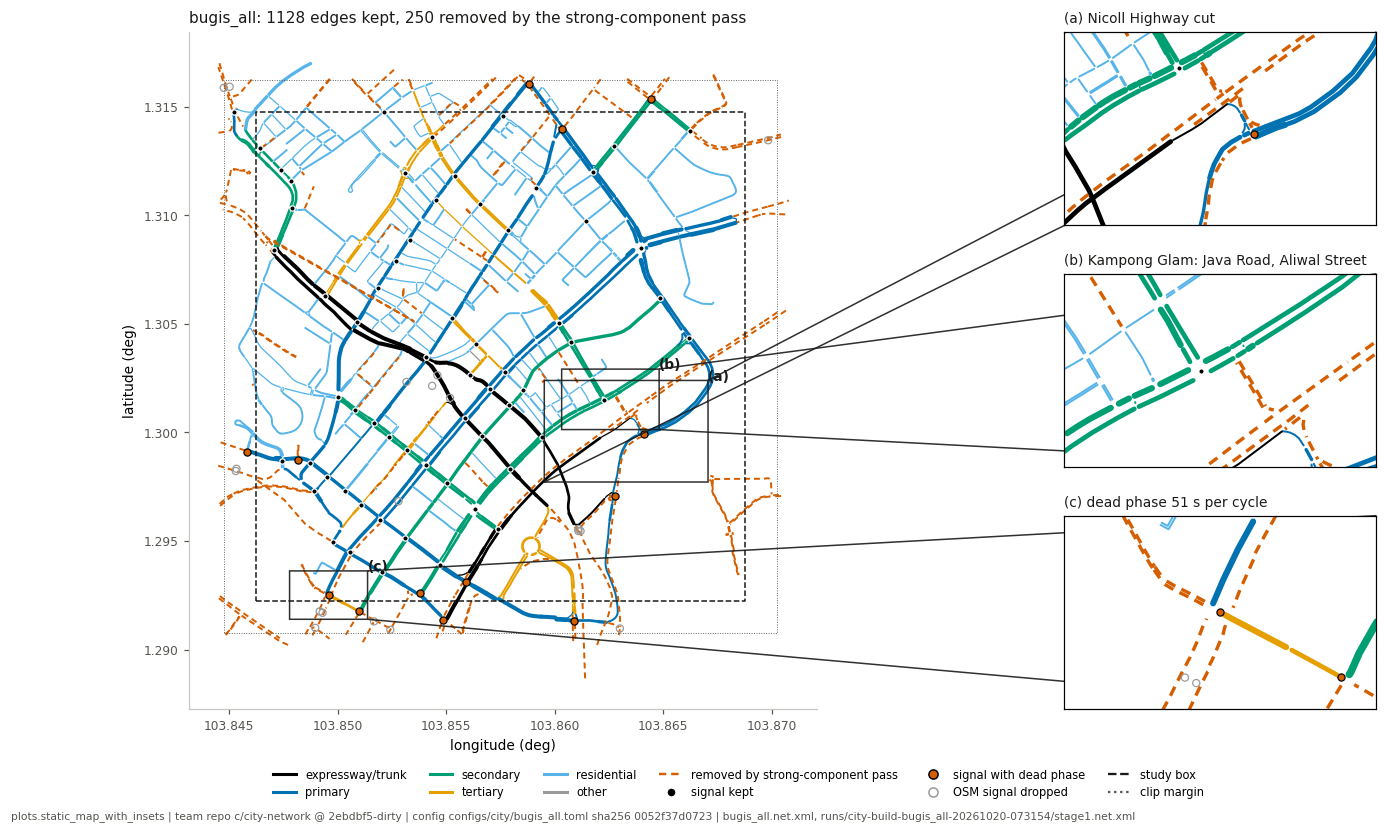

In [8]:
def centre(names):
    x = removed[removed["name"].isin(names)]
    return (x["mid_lon"].mean(), x["mid_lat"].mean())
worst = DEAD_TLS.iloc[0]
INSETS = [dict(label="Nicoll Highway cut", center=centre(["Nicoll Highway"]), half_m=420),
          dict(label="Kampong Glam: Java Road, Aliwal Street", center=centre(["Java Road", "Aliwal Street"]), half_m=250),
          dict(label=f"dead phase {worst['dead s / cycle, now']:.0f} s per cycle", center=(worst["lon"], worst["lat"]), half_m=200)]
cap = (f"plots.static_map_with_insets | team repo {PROV['branch']} @ {PROV['commit']} | config {CFG['_path']} sha256 {CFG['_sha256']} | "
       f"{NETF.name}, {META['build_run_dir']}/stage1.net.xml")
fig = plots.static_map_with_insets(fin, removed, SIG, box=BOX, clip_margin_deg=MARGIN, insets=INSETS,
                                   title=f"{NAME}: {len(fin)} edges kept, {len(removed)} removed by the strong-component pass", caption=cap)
plt.show()

What to notice: (a) The south-eastern stretch of Nicoll Highway goes as one long piece from the kept grid to the box edge, together with its slip roads. Once the expressways are excluded, its traffic has no way back (a sink, §7). (b) Java Road and Aliwal Street in Kampong Glam lose 0.46 lane-km, 600–880 m inside the box, far from any side, so moving a side cannot recover them. Aliwal Street is one-way, but most of the removed Java Road is two-way, so the one-way mechanism of §7 does not explain them alone; their cause is not traced (ASSUMED from the map, not traced: their link to the removed Nicoll Highway beside them, inset (a)). (c) The junction with the 51 s dead phase sits on the south side at Coleman Street and Hill Street; the pass removed three of its four approaches (§10).

## 7. Should the box sides cross arterials rather than run along them? (T1-D11)

**How the cut works.** netconvert imports only the roads inside the *clip limit*: the study box plus 0.0015 deg (about 167 m) on every side. Everything beyond is cut off. The strong-component pass then keeps only roads from which a car can reach every other road and come back. A cut does harm only when it leaves a one-way piece. That piece is a one-way street, or one carriageway of a divided road, because OSM draws each carriageway as its own one-way road. A one-way piece whose far end was cut off is a **sink** (cars can enter but never leave) or a **source** (cars can leave but never enter). The pass deletes it back to the last junction where it connects both ways. A cut two-way road usually survives, because netconvert adds a U-turn where it dead-ends (T1-D5).

**When the cut crosses a road** (panel b), it cuts each carriageway once. The lost pieces run from the cut to the first junction, which usually lies in the margin, so the arterial survives inside the box.

**When the cut runs along a road** (panel a), the outer carriageway and the side streets beyond it are cut at every junction along the side. If the outer carriageway's only exits are those cut streets, it becomes a sink along its whole length. It is removed with the one-way streets that only feed it. The pilot saw this once: the first Toa Payoh download put the box edge on Braddell Road, and most of Braddell Road fell out (a pilot result in C's private notes, not shared; not re-run here).

**In short:** a cut across a road costs two short stubs, and a cut along a road can cost the whole road. Because the 167 m margin moves the cut outward, the road at risk is the one along the *clip limit*, not the one along the box side.

**Measured below on the real rim:** every stage-1 road within 300 m inside a side or in the margin. A road counts as "along" its nearest side when it runs within 30 deg of it, "crossing" above 60 deg and "oblique" in between (the angles are C's choice). Arterial means trunk, primary, secondary or tertiary.

In [9]:
W, S, E, N = BOX
def rim_relation(r):
    """Nearest box side, distance inside it (m, negative = in the margin) and angle class to that side."""
    d = {"W": (r.mid_lon - W), "E": (E - r.mid_lon), "S": (r.mid_lat - S), "N": (N - r.mid_lat)}
    side = min(d, key=d.get)
    (x0, y0), (x1, y1) = r.coords[0], r.coords[-1]
    ang = math.degrees(math.atan2(abs(y1 - y0), abs(x1 - x0)))          # 0 = east-west
    a = ang if side in "NS" else 90 - ang                                 # angle to the side
    return pd.Series({"side": side, "dist_in_m": d[side] * cm.M_PER_DEG,
                      "relation": "along" if a < 30 else "oblique" if a < 60 else "crossing"})
s1 = pd.concat([s1.drop(columns=[c for c in ("side", "dist_in_m", "relation") if c in s1]), s1.apply(rim_relation, axis=1)], axis=1)
s1["arterial"] = s1["klass"].isin(["expressway/trunk", "primary", "secondary", "tertiary"])
RIM_M = 300
rim = s1[s1["dist_in_m"] < RIM_M].copy()
rim["where"] = np.where(rim["dist_in_m"] < 0, "margin", f"inside, 0-{RIM_M} m")
tab = (rim[rim["arterial"]].groupby(["relation", "where"])
       .apply(lambda d: pd.Series({"lane-km": d.lane_m.sum() / 1000, "removed lane-km": d.loc[~d.kept, "lane_m"].sum() / 1000}), include_groups=False)
       .unstack("where"))
for w_ in ("margin", f"inside, 0-{RIM_M} m"):
    tab[("removed share", w_)] = tab[("removed lane-km", w_)] / tab[("lane-km", w_)]
display(tab.round(2).reindex(["along", "oblique", "crossing"]))
ow = rim.groupby("oneway").apply(lambda d: d.loc[~d.kept, "lane_m"].sum() / d.lane_m.sum(), include_groups=False)
print(f"Removed share of rim lane length: one-way roads {ow.get(True, 0):.0%}, two-way roads {ow.get(False, 0):.0%}")
along_lost = rim[rim.arterial & (rim.relation == "along") & ~rim.kept].groupby(["side", "name"]).agg(
    removed_lane_km=("lane_m", lambda v: v.sum() / 1000), nearest_m=("dist_in_m", "max"), farthest_m=("dist_in_m", "min"))
print("Arterials running along a side that lost length (distance inside the side, m; negative = in the margin):")
display(along_lost.sort_values("removed_lane_km", ascending=False).round(2).head(6))
inside_lost = rim[rim.arterial & (rim.relation != "along") & ~rim.kept & (rim.dist_in_m >= 0)]
print("Largest losses inside the box, on arterials that cross a side or meet it at an angle (lane-km):")
display(inside_lost.groupby(["side", "name", "oneway"]).lane_m.sum().div(1000).round(2).sort_values(ascending=False).head(8).to_frame("removed lane-km"))

lane-km        removed lane-km        removed share  \
where    inside, 0-300 m margin inside, 0-300 m margin        margin   
relation                                                               
along               5.28   5.41            0.00   2.44          0.45   
oblique            28.72  14.44            6.06  10.65          0.74   
crossing           16.43  10.75            8.00   9.59          0.89   

                          
where    inside, 0-300 m  
relation                  
along               0.00  
oblique             0.21  
crossing            0.49

Removed share of rim lane length: one-way roads 43%, two-way roads 33%
Arterials running along a side that lost length (distance inside the side, m; negative = in the margin):


removed_lane_km  nearest_m  farthest_m
side name                                                     
W    Thomson Road                  1.59     -63.95     -154.73
     Cavenagh Road                 0.35    -147.94     -147.94
S    Coleman Street                0.17    -135.03     -135.03
     Raffles Boulevard             0.12    -129.13     -129.13
W    Keng Lee Road                 0.11    -125.68     -125.68
     Cavenagh road                 0.08    -150.73     -150.73

Largest losses inside the box, on arterials that cross a side or meet it at an angle (lane-km):


removed lane-km
side name               oneway                 
E    Nicoll Highway     True               2.05
S    Republic Boulevard True               1.32
     Ophir Road         True               1.30
     East Coast Parkway True               1.22
W    Fort Canning Link  True               1.21
E    Boon Keng Road     True               1.18
W    Fort Canning Road  False              1.07
     Bukit Timah Road   True               1.06

What to look at: in panels (a) and (b), the vermillion pieces, which the strong-component pass deletes; in panel (c), whether the thick lines (arterials running along a side) or the thin ones (arterials crossing it) turn vermillion, and whether that happens inside the dashed box or in the margin beyond it.

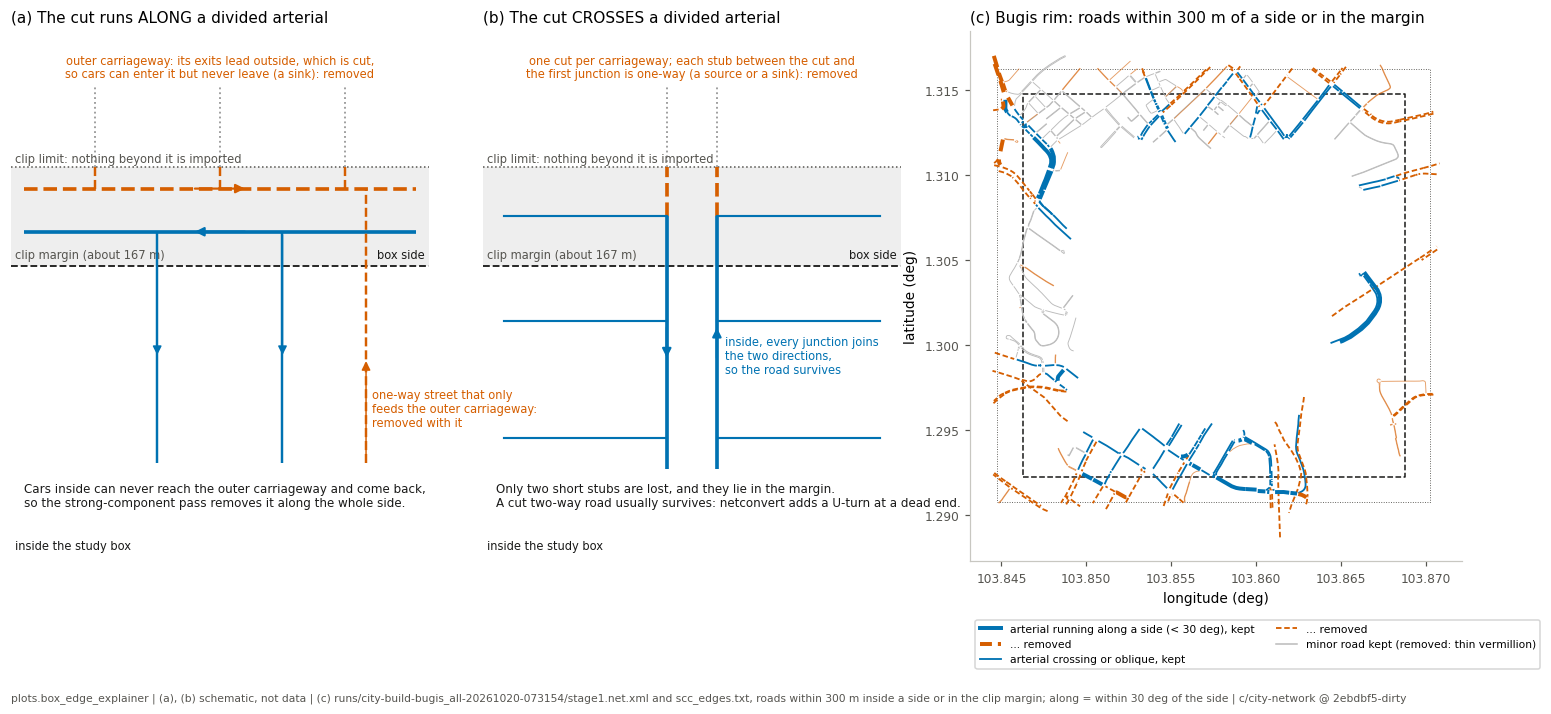

In [10]:
cap = (f"plots.box_edge_explainer | (a), (b) schematic, not data | (c) {META['build_run_dir']}/stage1.net.xml and scc_edges.txt, "
       f"roads within {RIM_M} m inside a side or in the clip margin; along = within 30 deg of the side | {PROV['branch']} @ {PROV['commit']}")
fig = plots.box_edge_explainer(rim, BOX, MARGIN, rim_m=RIM_M, caption=cap)
plt.show()

> **Update 2026-10-21:** C ruled T1-D11 on 2026-10-20: keep the sides. The interior trace is still open.

What to notice: arterials that run along a side lost **nothing** inside the box (0.00 of 5.28 lane-km within 300 m of a side). Thomson Road on the west, which runs 64–155 m outside the box next to the clip limit, accounts for most of the "along" loss: 1.59 of the 2.44 lane-km lost in the margin. Cavenagh Road, Coleman Street, Raffles Boulevard and Keng Lee Road lose 0.08–0.35 lane-km each, 126–151 m outside the box.

Most of the length lost inside the rim is on crossing or oblique arterials: 8.00 of 16.43 lane-km crossing and 6.06 of 28.72 oblique. The eight largest losses shown in the table cover 10.4 of these 14.1 lane-km. Seven of the eight are one-way roads that lead to the excluded expressways or run a long way without a junction (the south-eastern stretch of Nicoll Highway, Republic Boulevard, Ophir Road, East Coast Parkway, Fort Canning Link, Boon Keng Road, Bukit Timah Road); Fort Canning Road (1.07 lane-km) is two-way. Moving a side would not bring them back, because the cause is the expressway exclusion (T1-D2), not the side's direction. One-way roads are removed more often than two-way roads, but not overwhelmingly: 43 % against 33 % of rim lane length. So the one-way mechanism is one cause among several.

**What this means for T1-D11** (C's recommendation, ruled 2026-10-20): keep the box sides where they are. The arterials running along the sides inside the box are intact. The losses come from the expressway exclusion and from interior pockets of small streets (Kampong Glam, Queen Street), and the position of a side changes neither. What remains of T1-D11 is the interior trace (6.46 lane-km removed more than 600 m inside the box), still open on 2026-10-21.

- VERIFIED: the rim numbers above, computed in this notebook from the stage-1 net and the kept-edge list.
- ASSUMED: the causes named for the crossing losses. They are inferred from road names and one-way flags, not traced junction by junction.

**What these losses do to the experiment** (C's reasoning, 2026-10-20; not simulated unless marked):

- **Network density stays exact.** Density is vehicles ÷ the lane length of the *kept* network (179.81 lane-km). A removed road is simply not part of the experiment, so it does not bias the denominator; the results describe the kept network, and the report must say so.
- **Traffic is rerouted, not lost.** Demand is synthetic and every trip runs on kept roads, so no flow disappears. Trips that in reality would use the removed stretch of Nicoll Highway or the expressway links must use interior arterials instead, which can make junctions near the rim busier than in reality. ASSUMED: not simulated.
- **Some LTA stretches cannot be compared.** The task 2 teammate notebook in the same folder finds 278 LTA stretches inside the box on roads this cleaning removed (its §6). Member E's hotspot comparison must leave them out and report how many were left out.
- **The side orientation causes none of this in Bugis.** All three effects come from the expressway exclusion and interior one-way pockets, which moving a box side would not change. That is why the recommendation above is to keep the sides.

## 8. Where the lane length goes (pipeline funnel)

What to look at: how much each stage takes away from the first bar, and in which colour. Every bar counts only road length inside the clip limit (study box plus 0.0015 deg, about 167 m), so the stages compare like with like.

,expressway/trunk,primary,secondary,tertiary,residential,other,total
OSM download\n(car roads),64.43,92.13,48.17,25.82,71.34,128.77,430.66
"class filter\n(no motorway, service)",45.68,92.13,48.17,25.82,71.34,0.61,283.74
netconvert\nstage 1,40.10,74.20,38.94,18.82,59.22,0.55,231.83
strong component\n(final net),21.90,59.97,32.91,14.29,50.00,0.07,179.14


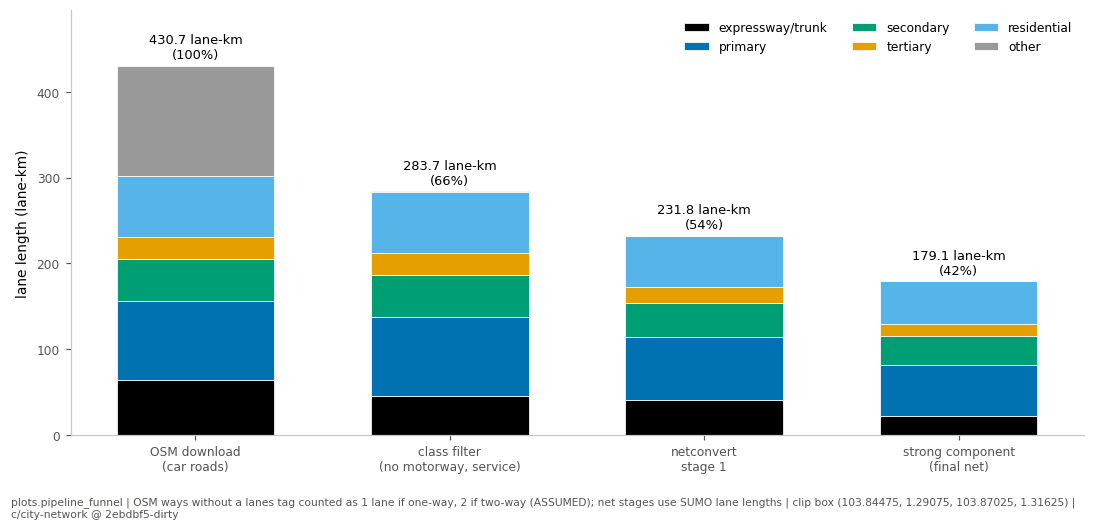

In [11]:
funnel = pd.DataFrame({
    "OSM download\n(car roads)": cm.osm_lane_km(ways, CLIP),
    "class filter\n(no motorway, service)": cm.osm_lane_km(ways[~ways.highway.isin(["motorway", "motorway_link", "service"])], CLIP),
    "netconvert\nstage 1": cm.lane_km_in_box(s1, CLIP),
    "strong component\n(final net)": cm.lane_km_in_box(fin, CLIP)}).T
display(funnel.round(2).assign(total=funnel.sum(axis=1).round(2)))
cap = ("plots.pipeline_funnel | OSM ways without a lanes tag counted as 1 lane if one-way, 2 if two-way (ASSUMED); net stages use SUMO lane lengths | "
       f"clip box {tuple(round(v, 5) for v in CLIP)} | {PROV['branch']} @ {PROV['commit']}")
fig = plots.pipeline_funnel(funnel, caption=cap)
plt.show()

What to notice: the class filter removes the most, 147 lane-km (430.7 → 283.7), almost all of it service roads (grey: driveways and car parks) plus 19 lane-km of expressway. That is the T1-D2 choice working as intended. netconvert stage 1 removes another 52 lane-km across every class. This is ASSUMED to be mostly road length inside junctions, which SUMO keeps as internal lanes outside the normal-lane total (the final net has 43.6 km of internal lanes, `meta.json`). The OSM lane-count assumption for untagged ways adds some error. The strong-component pass removes 52.7 lane-km, and the black expressway/trunk bar loses the most: 40.1 → 21.9 lane-km (45 %), mainly the south-eastern stretch of Nicoll Highway and its slip roads.

The funnel counts only lane length inside the clip limit, so its last bar (179.14 lane-km) need not equal the net's total of 179.81 lane-km.

## 9. Tag coverage and edge lengths

What to look at: on the left, the residential bars, which show how many edges rest on the 50 km/h fallback speed (T1-D6) and on netconvert's default lane count; on the right, the gap between the solid curve (share of edges) and the dashed curve (share of lane length) left of the 50 m line.

0 of 1128 edges have no OSM way in the tiles (counted as untagged)


,n,lanes_tagged,maxspeed_tagged
klass,,,
expressway/trunk,52,52,51
other,1,0,0
primary,221,220,220
residential,575,556,568
secondary,138,138,136
tertiary,141,141,137


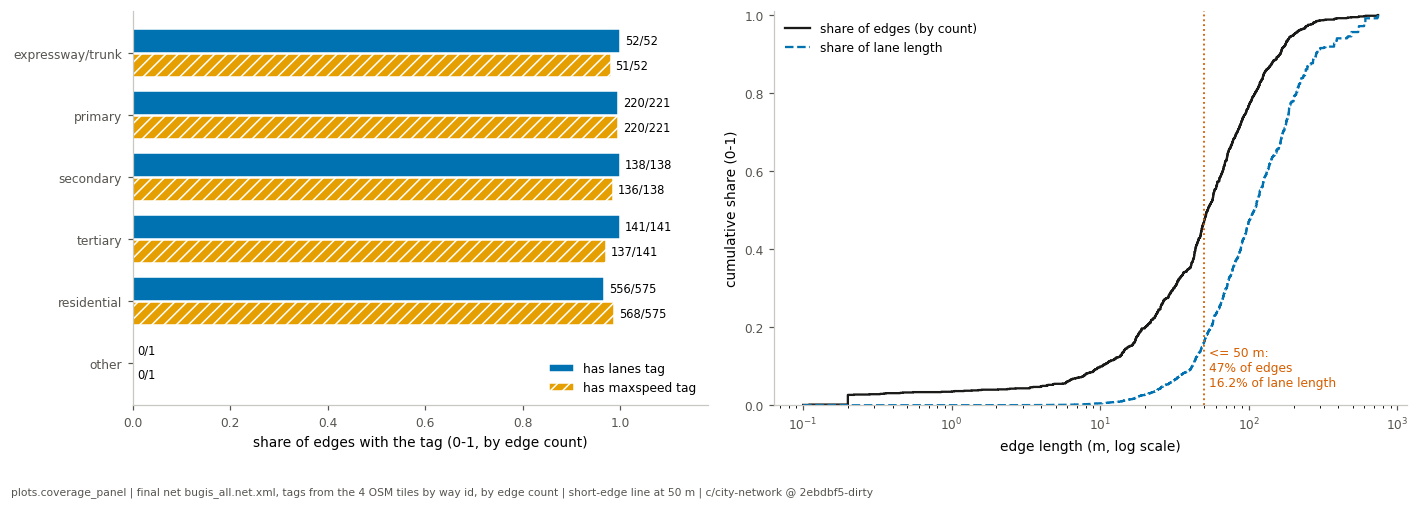

In [12]:
w = ways.set_index("id")
cov = fin.assign(lanes_tagged=fin.osm_way.map(w["lanes_tag"].notna()).fillna(False).astype(bool),
                 maxspeed_tagged=fin.osm_way.map(w["maxspeed_tag"].notna()).fillna(False).astype(bool),
                 found=fin.osm_way.isin(w.index))
tags = cov.groupby("klass").agg(n=("id", "size"), lanes_tagged=("lanes_tagged", "sum"), maxspeed_tagged=("maxspeed_tagged", "sum"))
print(f"{(~cov.found).sum()} of {len(cov)} edges have no OSM way in the tiles (counted as untagged)")
display(tags)
cap = f"plots.coverage_panel | final net {NETF.name}, tags from the 4 OSM tiles by way id, by edge count | short-edge line at 50 m | {PROV['branch']} @ {PROV['commit']}"
fig = plots.coverage_panel(tags, fin["length_m"].to_numpy(), fin["lane_m"].to_numpy(), short_m=50, caption=cap)
plt.show()

What to notice: OSM tagging is nearly complete in this download. 556 of 575 residential edges carry a `lanes` tag and 568 of 575 a `maxspeed` tag, so the 50 km/h fallback (T1-D6) sets the speed of only 7 residential edges. This disagrees with an earlier figure in C's private notes, not shared (66 % of minor roads with a `lanes` tag, 39 % with `maxspeed`), measured on a basis those notes do not restate. The discrepancy is still unresolved on 2026-10-21, so neither figure should be quoted yet. On the right, 47 % of edges are 50 m or shorter, but they hold only 16.2 % of the lane length. Weighting clusters by lane length (T3-D2) instead of by edge count therefore changes the picture a lot. A few percent of edges are shorter than 1 m: stubs left by junction joining (ASSUMED).

> **Update 2026-10-21:** in the figure, "current" means the plan before the rebuild (commit 29247c1), and "rebuilt" is the plan now committed at 4e95539: a re-run of the same rebuild on 2026-10-21 matched the committed plans for all 76 signals. The figure's labels date from 2026-10-20 and cannot change without a re-run.

## 10. Signal cycles before and after the rebuild

What to look at: the hatched vermillion bars. Each is green given to a road that no longer exists, and every remaining approach of that junction is red meanwhile. The four junctions shown have the longest dead time; the table in §3.1 lists all of them. Each pair of rows is one junction: the current plan above, the plan `netconvert --tls.rebuild` writes below.

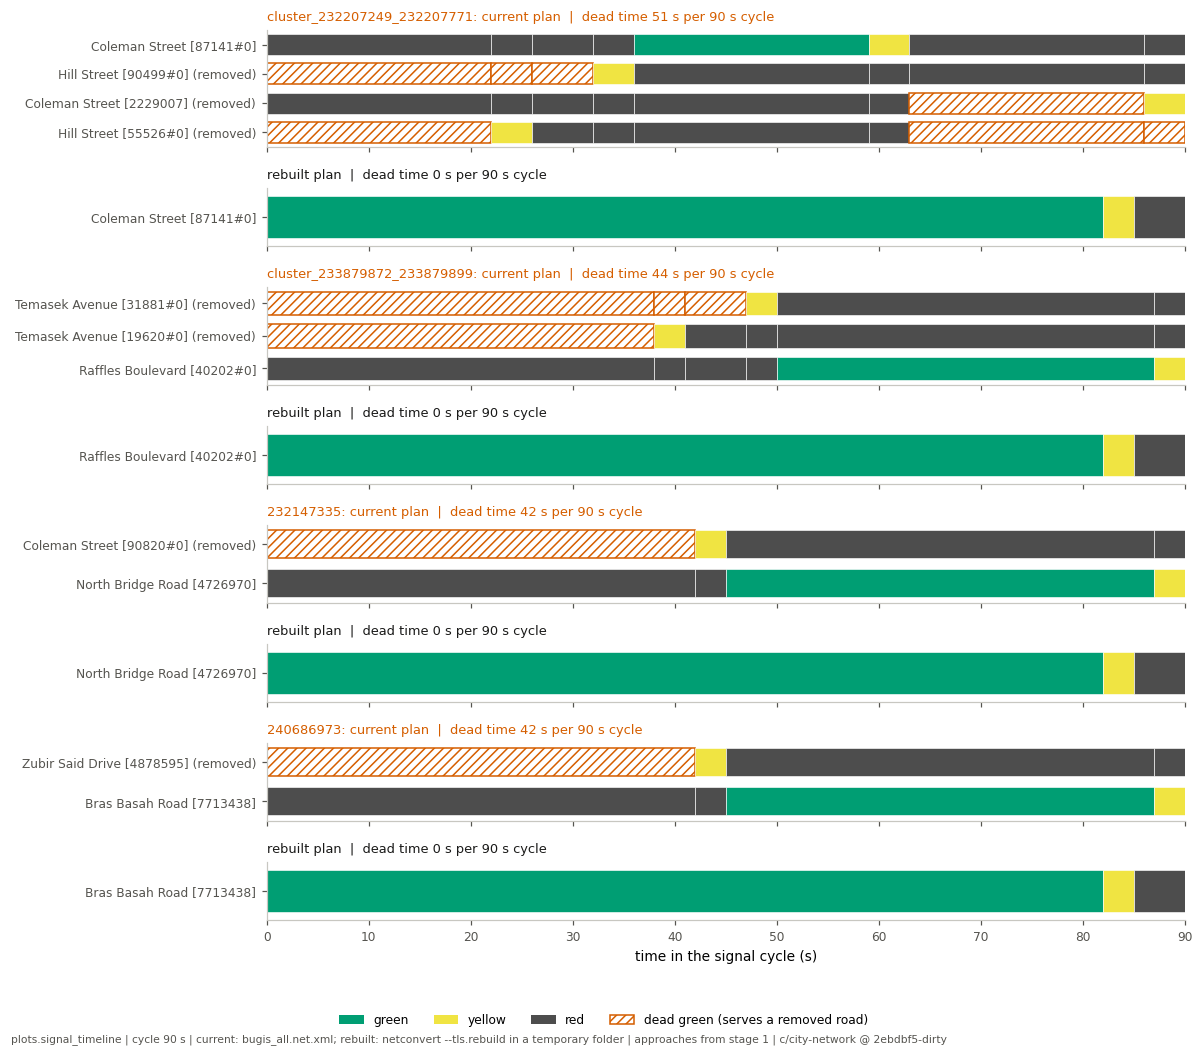

In [13]:
names = dict(zip(s1["id"], s1["name"]))
def approaches(tl, plan, ref_links, removed_ok):
    """Rows for plots.signal_timeline: one per incoming edge, links that still exist (or all, if none do)."""
    left = set(plan["links"].values())
    out = []
    for frm, idx in sorted(ref_links["approaches"].items(), key=lambda kv: min(kv[1])):
        keep = [i for i in idx if i in left]
        lab = f"{(names.get(frm) or '(unnamed)')[:20]} [{frm[-7:]}]"
        out.append(dict(label=lab, removed=removed_ok and not keep, links=keep or idx))
    return out
JUNCTIONS = []
for tl in DEAD_TLS["signal"].head(4):
    cur, new = plans[tl], plans_new[tl]
    JUNCTIONS.append(dict(title=tl[:34], plans=[
        dict(label="current", dead_s=cm.dead_time(cur, 5), phases=cur["phases"], approaches=approaches(tl, cur, plans_s1[tl], True)),
        dict(label="rebuilt", dead_s=cm.dead_time(new, 5), phases=new["phases"], approaches=approaches(tl, new, new, False))]))
cap = f"plots.signal_timeline | cycle {NETCFG['tls_cycle_s']} s | current: {NETF.name}; rebuilt: netconvert --tls.rebuild in a temporary folder | approaches from stage 1 | {PROV['branch']} @ {PROV['commit']}"
fig = plots.signal_timeline(JUNCTIONS, caption=cap)
plt.show()

> **Update 2026-10-21:** the one-road question became its own decision, T1-D12, and it covers 13 signals, not these 4. After the rebuild 13 signals control a single road: 10 lost their other roads to the strong-component pass and 3 had one road from the start (C's one-road-signals check, in C's private notes; it needs the git-ignored stage-1 net). These are not the 13 dead-phase signals of §3.1: 9 signals are in both sets, 4 dead-phase signals still control two roads each after the rebuild, and 4 one-road signals never had a dead phase. Each one-road signal gives its road 80–86 s of green per 90 s cycle. C ruled to keep all 13 as signals (2026-10-20); the group's reply is due Thu 22 Oct 18:00 SGT.

What to notice: at Coleman Street and Hill Street (`cluster_232207249_232207771`), three removed approaches take 51 s of every 90 s cycle. The one remaining approach, Coleman Street, gets only 23 s of green; the rebuilt plan gives it 82 s. The other three junctions show the same pattern: the remaining road gets 37–42 s of green now and 82 s after the rebuild. After the rebuild, each of these junctions controls a single approach, so its signal no longer separates conflicting traffic. Whether to keep such one-approach signals (stand-ins for pedestrian crossings) or turn them into plain junctions became decision T1-D12.

## 11. Verified and assumed

| Claim | Status | How |
|---|---|---|
| Before the rebuild, 13 signals had dead phases of 6–51 s per 90 s cycle; SUMO warned about only 7 of them | VERIFIED | §3.1, from the plans and link numbers; kept link numbers equal stage 1 (0 differ) |
| `netconvert --tls.rebuild` removes every dead phase and keeps 1,128 edges and 3,020 connections | VERIFIED | §4 checks 9 and 10, rebuild in a temporary folder |
| The rebuilt plans drawn in §10 equal the plans committed at 4e95539 | VERIFIED 2026-10-21 | the §3 netconvert command re-run on the 29247c1 build run: 76 of 76 plans identical |
| 13 one-road signals after the rebuild; 9 of them are also among the 13 dead-phase signals | VERIFIED 2026-10-21 | signal-controlled roads counted from the connections of the nets at 29247c1 and 4e95539 |
| Arterials along a side lost 0 lane-km inside the box; Thomson Road lost 1.59 lane-km in the margin | VERIFIED | §7, with the stated 30 deg and 300 m definitions |
| The rim losses inside the box come from expressway-bound one-way roads | ASSUMED | inferred from names and one-way flags, not traced |
| Braddell Road fell out when the Toa Payoh box ran along it | ASSUMED here | a pilot result in C's private notes (not shared), not re-run |
| 16 OSM signals were dropped as mid-block crossings | ASSUMED (lower bound) | 50 m distance rule, §5 |
| netconvert's 52 lane-km drop is mostly junction interiors | ASSUMED | consistent with 43.6 km of internal lanes; not split out |
| Untagged OSM ways have 1 lane if one-way, 2 if two-way | ASSUMED | used only for the first two funnel bars |
| The interactive map does not render on GitHub | ASSUMED | GitHub's notebook viewer does not run the map's JavaScript; not checked on this copy |

**Reproduce.** This copy cannot be re-run by a teammate as it stands; "How to read this copy" at the top lists what a re-run needs.